In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

print("Libraries imported")

Libraries imported


In [2]:
iris = load_iris()
X = iris.data
y = iris.target

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print()
print("Feature names:", iris.feature_names)
print("Class names:", iris.target_names)
print()
print("First 5 rows of X:")
print(X[:5])
print()
print("First 5 labels:", y[:5])

Shape of X: (150, 4)
Shape of y: (150,)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']

First 5 rows of X:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

First 5 labels: [0 0 0 0 0]


In [3]:
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in y]

print("Dataset shape:", df.shape)
print()
print("First 5 rows:")
print(df.head())
print()
print("Class distribution:")
print(df['species'].value_counts())

Dataset shape: (150, 5)

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)
print()
print("Train class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))

Train size: (120, 4)
Test size: (30, 4)

Train class counts: [40 40 40]
Test class counts: [10 10 10]


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling done")
print("Train mean:", X_train_scaled.mean(axis=0).round(3))
print("Train std:", X_train_scaled.std(axis=0).round(3))

Scaling done
Train mean: [-0. -0.  0.  0.]
Train std: [1. 1. 1. 1.]


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(kernel='rbf', random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

print("Models initialized:")
for name in models:
    print(" -", name)

Models initialized:
 - Logistic Regression
 - Decision Tree
 - Random Forest
 - SVM
 - KNN
 - Naive Bayes


In [7]:
results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')

    results.append([name, round(prec, 4), round(rec, 4), round(acc, 4)])
    print(f"Trained {name}")

print()
print("All models trained and evaluated")

Trained Logistic Regression
Trained Decision Tree
Trained Random Forest
Trained SVM
Trained KNN
Trained Naive Bayes

All models trained and evaluated


In [8]:
df_results = pd.DataFrame(
    results,
    columns=["Algorithm", "Precision", "Recall", "Accuracy"]
)

df_results = df_results.sort_values("Accuracy", ascending=False).reset_index(drop=True)

print("Comparison of Classification Algorithms")
print("=" * 60)
print(df_results.to_string(index=False))

Comparison of Classification Algorithms
          Algorithm  Precision  Recall  Accuracy
        Naive Bayes     0.9697  0.9667    0.9667
                SVM     0.9697  0.9667    0.9667
      Decision Tree     0.9333  0.9333    0.9333
Logistic Regression     0.9333  0.9333    0.9333
                KNN     0.9444  0.9333    0.9333
      Random Forest     0.9024  0.9000    0.9000


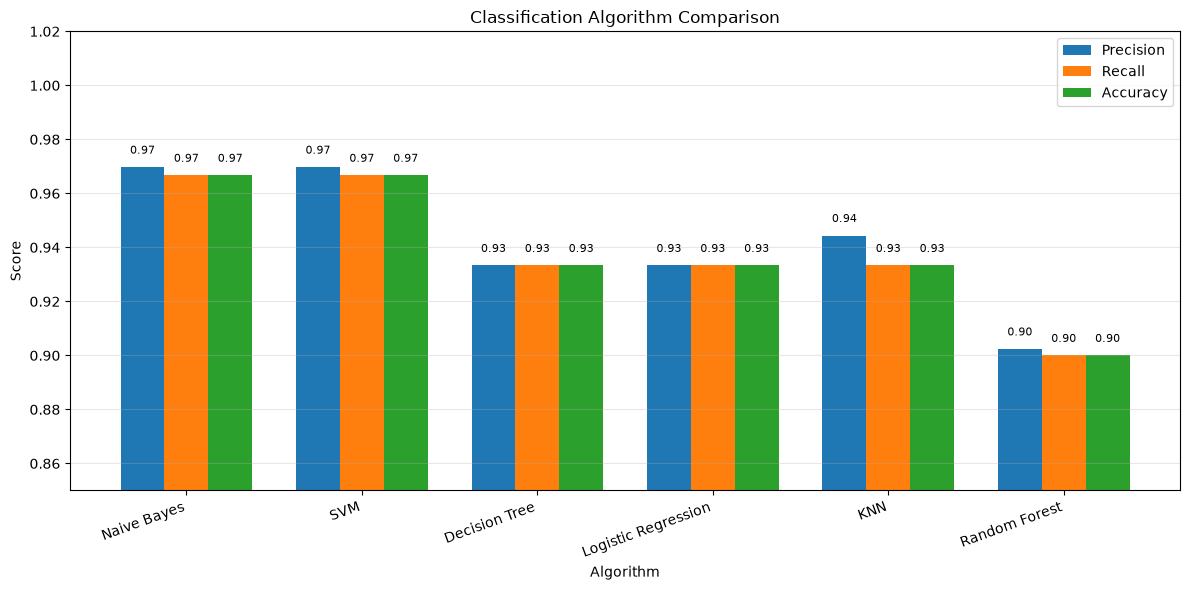

In [9]:
metrics = ["Precision", "Recall", "Accuracy"]
x = np.arange(len(df_results["Algorithm"]))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for i, metric in enumerate(metrics):
    offset = (i - 1) * width
    bars = ax.bar(x + offset, df_results[metric], width, label=metric)

    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.005,
                f"{h:.2f}", ha='center', fontsize=8)

ax.set_xlabel("Algorithm")
ax.set_ylabel("Score")
ax.set_title("Classification Algorithm Comparison")
ax.set_xticks(x)
ax.set_xticklabels(df_results["Algorithm"], rotation=20, ha='right')
ax.set_ylim(0.85, 1.02)
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

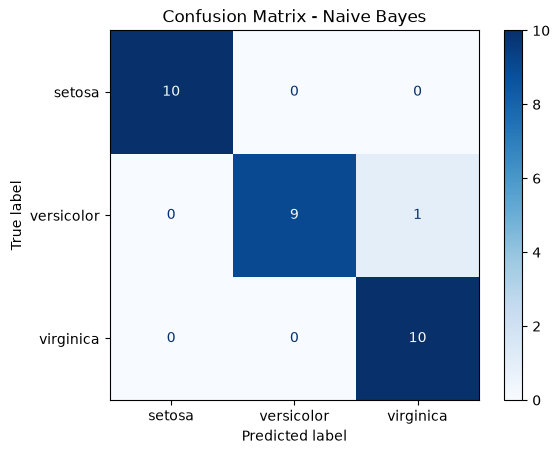

Best model: Naive Bayes


In [10]:
best_name = df_results.iloc[0]["Algorithm"]
best_model = models[best_name]

y_pred_best = best_model.predict(X_test_scaled)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap='Blues')
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

print(f"Best model: {best_name}")